In [45]:
import random, time, copy
import numpy as np
import torch, torchvision

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

PyTorch: 2.11.0+cu130
Torchvision: 0.26.0+cu130
Device: cuda | Tesla T4


In [46]:
from pathlib import Path

BASE_DIR = Path("/content/dataset_raw")
CLASSES = ["chair", "door"]

for kelas in CLASSES:
    (BASE_DIR / kelas).mkdir(parents=True, exist_ok=True)

print("Struktur folder dataset:")

for kelas in CLASSES:
    print(f"- {kelas}: {BASE_DIR / kelas}")

Struktur folder dataset:
- chair: /content/dataset_raw/chair
- door: /content/dataset_raw/door


In [47]:
%pip install -U -q gdown

In [48]:
import os, gdown
from pathlib import Path

BASE_DIR = "/content/dataset_raw/door"
os.makedirs(BASE_DIR, exist_ok=True)

FOLDERS = {
    "test/Closed": "13ntdy8r92TtTNlqE84N0VnhtV9u6o4hp",
    "test/Open": "1ZUG6O5MAWI0mt8HDP8Tdx0M9DSBDx0AW",
    "test/Semi": "1ItceVaPcVMO9fpj847jtigjkwaOQItsG",
    "train/Closed": "1lBrEKC_slJcMlx_kfrOulI-uLe_5OS3t",
}

for nama, fid in FOLDERS.items():
    out = os.path.join(BASE_DIR, nama)
    os.makedirs(out, exist_ok=True)
    if any(Path(out).glob("*.png")):
        print("Lewati", nama); continue
    print("Mengunduh:", nama)
    try:
        gdown.download_folder(id=fid, output=out, quiet=True, remaining_ok=True)
    except Exception as e:
        print("Gagal", nama, e)

for sub in sorted(Path(BASE_DIR).glob("*/*")):
    print(sub.relative_to(BASE_DIR), len(list(sub.glob("*.png"))))

Lewati test/Closed
Lewati test/Open
Lewati test/Semi
Lewati train/Closed
test/Closed 20
test/Open 20
test/Semi 20
train/Closed 50


In [49]:
import requests, time
from pathlib import Path

CHAIR_DIR = Path("/content/dataset_raw/chair")
CHAIR_DIR.mkdir(parents=True, exist_ok=True)
TARGET = 100
API = "https://commons.wikimedia.org/w/api.php"
HEADERS = {"User-Agent": "RET503-student-project/1.0 (tugas kuliah)"}
params = {
    "action": "query", "format": "json", "generator": "search",
    "gsrsearch": "chair furniture", "gsrnamespace": 6, "gsrlimit": 50,
    "prop": "imageinfo", "iiprop": "url|mime", "iiurlwidth": 640,
}

n = len(list(CHAIR_DIR.glob("*.jpg")))
cont = {}
while n < TARGET:
    r = requests.get(API, params={**params, **cont}, headers=HEADERS, timeout=30).json()
    for p in r.get("query", {}).get("pages", {}).values():
        info = p.get("imageinfo", [{}])[0]
        if info.get("mime") != "image/jpeg" or "thumburl" not in info:
            continue
        out = CHAIR_DIR / f"chair_{p['pageid']}.jpg"
        if out.exists():
            continue
        try:
            img = requests.get(info["thumburl"], headers=HEADERS, timeout=30)
            img.raise_for_status()
            out.write_bytes(img.content)
            n += 1
        except Exception as e:
            print("Lewati:", e)
        time.sleep(0.5)
        if n >= TARGET:
            break
    if "continue" not in r:
        break
    cont = r["continue"]
print("Gambar chair (.jpg):", n)

Gambar chair (.jpg): 100


chair: 100 gambar -> OK
door: 110 gambar -> OK


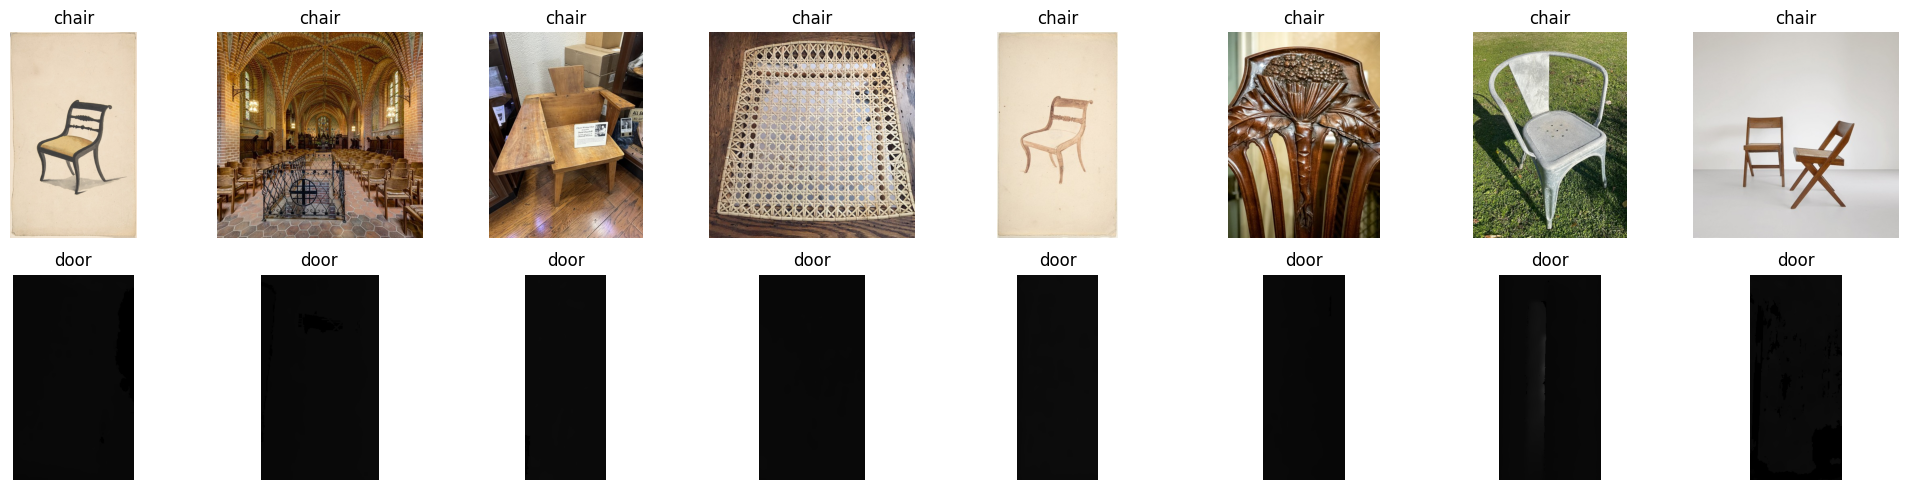

In [50]:
import random
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

BASE_DIR = Path("/content/dataset_raw")
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
MIN_PER_CLASS = 50

files = {}
for kelas in ["chair", "door"]:
    files[kelas] = sorted(p for p in (BASE_DIR / kelas).rglob("*") if p.suffix.lower() in EXT)
    n = len(files[kelas])
    print(f"{kelas}: {n} gambar -> {'OK' if n >= MIN_PER_CLASS else 'KURANG'}")

fig, axes = plt.subplots(2, 8, figsize=(20, 5))
for row, kelas in enumerate(files):
    for ax, p in zip(axes[row], random.sample(files[kelas], min(8, len(files[kelas])))):
        ax.imshow(Image.open(p).convert("RGB")); ax.set_title(kelas); ax.axis("off")
plt.tight_layout(); plt.show()

In [51]:
import csv, datetime as dt

rows = []
for kelas, paths in files.items():
    for p in paths:
        rows.append({
            "nama_file": str(p.relative_to(BASE_DIR)),
            "kelas": kelas,
            "tanggal": dt.date.fromtimestamp(p.stat().st_mtime).isoformat(),
            "kondisi_cahaya": "tidak_diketahui",
            "sumber": "google_drive" if kelas == "door" else "wikimedia_commons",
        })

with open(BASE_DIR / "metadata.csv", "w", newline="") as f:
    w = csv.DictWriter(f, fieldnames=list(rows[0].keys()))
    w.writeheader(); w.writerows(rows)
print(len(rows), "baris ->", BASE_DIR / "metadata.csv")

210 baris -> /content/dataset_raw/metadata.csv


In [52]:
import shutil
from PIL import Image

SPLIT_DIR = Path("/content/dataset")
BLOCK, VAL_RATIO = 10, 0.2
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)
rng = random.Random(SEED)

for kelas, paths in files.items():
    blocks = [paths[i:i + BLOCK] for i in range(0, len(paths), BLOCK)]
    rng.shuffle(blocks)
    n_val = max(1, round(len(blocks) * VAL_RATIO))
    for i, blk in enumerate(blocks):
        out = SPLIT_DIR / ("val" if i < n_val else "train") / kelas
        out.mkdir(parents=True, exist_ok=True)
        for p in blk:
            nama = "_".join(p.relative_to(BASE_DIR).parts[1:])
            # semua gambar diseragamkan: JPG 256x256
            Image.open(p).convert("RGB").resize((256, 256)).save(
                (out / nama).with_suffix(".jpg"), quality=90)

for s in ["train", "val"]:
    for kelas in files:
        print(s, kelas, len(list((SPLIT_DIR / s / kelas).glob("*"))))

train chair 80
train door 90
val chair 20
val door 20


In [53]:
import pandas as pd
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
EPOCHS, BATCH = 10, 16

tf_train = transforms.Compose([
    transforms.RandomResizedCrop(224), transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.3, 0.3, 0.3),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
tf_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

train_ds = datasets.ImageFolder(SPLIT_DIR / "train", tf_train)
val_ds = datasets.ImageFolder(SPLIT_DIR / "val", tf_val)
train_dl = DataLoader(train_ds, BATCH, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, BATCH, num_workers=2)
NUM_CLASSES = len(train_ds.classes)
print("Kelas:", train_ds.classes)

def build(mode):
    weights = None if mode == "scratch" else models.ResNet18_Weights.IMAGENET1K_V1
    m = models.resnet18(weights=weights)
    if mode in ("feature", "partial"):
        for p in m.parameters():
            p.requires_grad = False
    m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)   # head baru, otomatis trainable
    if mode == "partial":
        for p in m.layer4.parameters():
            p.requires_grad = True
    m = m.to(DEVICE)
    if mode == "feature":
        opt = torch.optim.Adam(m.fc.parameters(), lr=1e-3)
    elif mode == "partial":
        opt = torch.optim.Adam([{"params": m.layer4.parameters(), "lr": 1e-4},
                                {"params": m.fc.parameters(), "lr": 1e-3}])
    else:
        opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    return m, opt

def set_train(m, mode):
    m.train()
    trainable = {"feature": ("fc",), "partial": ("layer4", "fc")}.get(mode)
    if trainable:                       # lapisan beku tetap eval() (slide 11)
        for name, mod in m.named_children():
            if name not in trainable:
                mod.eval()

def evaluate(m):
    m.eval(); correct = 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            correct += (m(x).argmax(1) == y).sum().item()
    return correct / len(val_ds)

history, summary = {}, []
best_overall, best_state = 0, None
for mode in ["feature", "partial", "scratch"]:
    torch.manual_seed(SEED)
    m, opt = build(mode)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
    loss_fn = nn.CrossEntropyLoss()
    accs, best, ep90 = [], 0, None
    t0 = time.time()
    for ep in range(1, EPOCHS + 1):
        set_train(m, mode)
        for x, y in train_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad(); loss_fn(m(x), y).backward(); opt.step()
        sched.step()
        acc = evaluate(m); accs.append(acc); best = max(best, acc)
        if ep90 is None and acc >= 0.90:
            ep90 = ep
        if acc > best_overall:
            best_overall, best_state = acc, copy.deepcopy(m.state_dict())
        print(f"[{mode}] epoch {ep:2d}  val_acc={acc:.3f}")
    history[mode] = accs
    summary.append({"mode": mode, "akurasi_val_terbaik": round(best, 3),
                    "waktu_latih_detik": round(time.time() - t0, 1),
                    "epoch_akurasi_90": ep90 if ep90 else "tidak tercapai"})

torch.save(best_state, "/content/best_model.pt")

Kelas: ['chair', 'door']
[feature] epoch  1  val_acc=0.725
[feature] epoch  2  val_acc=1.000
[feature] epoch  3  val_acc=1.000
[feature] epoch  4  val_acc=1.000
[feature] epoch  5  val_acc=1.000
[feature] epoch  6  val_acc=1.000
[feature] epoch  7  val_acc=1.000
[feature] epoch  8  val_acc=1.000
[feature] epoch  9  val_acc=1.000
[feature] epoch 10  val_acc=1.000
[partial] epoch  1  val_acc=1.000
[partial] epoch  2  val_acc=1.000
[partial] epoch  3  val_acc=1.000
[partial] epoch  4  val_acc=1.000
[partial] epoch  5  val_acc=1.000
[partial] epoch  6  val_acc=1.000
[partial] epoch  7  val_acc=1.000
[partial] epoch  8  val_acc=1.000
[partial] epoch  9  val_acc=1.000
[partial] epoch 10  val_acc=1.000
[scratch] epoch  1  val_acc=0.625
[scratch] epoch  2  val_acc=1.000
[scratch] epoch  3  val_acc=1.000
[scratch] epoch  4  val_acc=1.000
[scratch] epoch  5  val_acc=1.000
[scratch] epoch  6  val_acc=1.000
[scratch] epoch  7  val_acc=1.000
[scratch] epoch  8  val_acc=1.000
[scratch] epoch  9  val

In [54]:
from sklearn.metrics import classification_report, confusion_matrix

m = models.resnet18()
m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
m.load_state_dict(best_state)
m = m.to(DEVICE).eval()

yt, yp = [], []
with torch.no_grad():
    for x, y in val_dl:
        yp += m(x.to(DEVICE)).argmax(1).cpu().tolist()
        yt += y.tolist()

print("Urutan kelas:", val_ds.classes)
print(confusion_matrix(yt, yp))
print(classification_report(yt, yp, target_names=val_ds.classes))

Urutan kelas: ['chair', 'door']
[[20  0]
 [ 0 20]]
              precision    recall  f1-score   support

       chair       1.00      1.00      1.00        20
        door       1.00      1.00      1.00        20

    accuracy                           1.00        40
   macro avg       1.00      1.00      1.00        40
weighted avg       1.00      1.00      1.00        40



   mode  akurasi_val_terbaik  waktu_latih_detik  epoch_akurasi_90
feature                  1.0               19.4                 2
partial                  1.0               26.4                 1
scratch                  1.0               13.2                 2


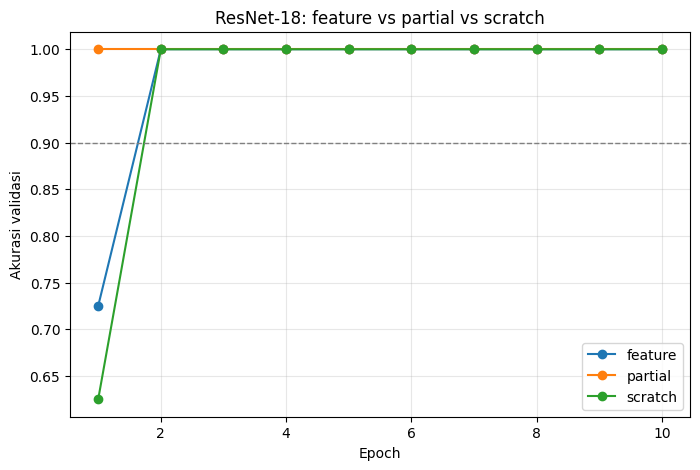

In [55]:
df = pd.DataFrame(summary)
print(df.to_string(index=False))
df.to_csv("/content/hasil_3_mode.csv", index=False)

plt.figure(figsize=(8, 5))
for mode, accs in history.items():
    plt.plot(range(1, EPOCHS + 1), accs, marker="o", label=mode)
plt.axhline(0.9, ls="--", c="gray", lw=1)
plt.xlabel("Epoch"); plt.ylabel("Akurasi validasi")
plt.title("ResNet-18: feature vs partial vs scratch")
plt.legend(); plt.grid(alpha=0.3)
plt.savefig("/content/grafik_akurasi.png", dpi=150, bbox_inches="tight")
plt.show()

In [56]:
def latency(m, device, n=100, warm=20):
    m = m.to(device).eval()
    x = torch.randn(1, 3, 224, 224, device=device)
    with torch.no_grad():
        for _ in range(warm):
            m(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        for _ in range(n):
            m(x)
        if device.type == "cuda":
            torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n * 1000

cands = {"ResNet-18": models.resnet18(weights=None),
         "MobileNetV3-Small": models.mobilenet_v3_small(weights=None)}
devices = ([torch.device("cuda")] if torch.cuda.is_available() else []) + [torch.device("cpu")]

rows = []
for name, m in cands.items():
    params = sum(p.numel() for p in m.parameters()) / 1e6
    for dev in devices:
        ms = latency(m, dev)
        rows.append({"model": name, "device": dev.type, "params_juta": round(params, 1),
                     "ms_per_frame": round(ms, 1), "fps": round(1000 / ms, 1)})
df_lat = pd.DataFrame(rows)
print(df_lat.to_string(index=False))
df_lat.to_csv("/content/hasil_latensi.csv", index=False)

            model device  params_juta  ms_per_frame   fps
        ResNet-18   cuda         11.7           3.7 273.9
        ResNet-18    cpu         11.7         152.6   6.6
MobileNetV3-Small   cuda          2.5          12.7  79.0
MobileNetV3-Small    cpu          2.5          25.4  39.4


In [57]:
from google.colab import files as gfiles

STAGE = Path("/content/submission")
if STAGE.exists():
    shutil.rmtree(STAGE)
shutil.copytree("/content/dataset_raw", STAGE / "dataset_raw")
(STAGE / "hasil").mkdir()
for f in ["hasil_3_mode.csv", "grafik_akurasi.png", "hasil_latensi.csv"]:
    shutil.copy(f"/content/{f}", STAGE / "hasil" / f)

shutil.make_archive("/content/submission", "zip", STAGE)
gfiles.download("/content/submission.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>